In [ ]:
!pip -q install pandas numpy scikit-learn joblib

In [ ]:
import re, json, os
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report
import joblib

RANDOM_STATE = 42


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("adisongoh/it-service-ticket-classification-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'it-service-ticket-classification-dataset' dataset.
Path to dataset files: /kaggle/input/it-service-ticket-classification-dataset


In [ ]:
df = pd.read_csv("/kaggle/input/it-service-ticket-classification-dataset/all_tickets_processed_improved_v3.csv")  # ajusta nombre
df.head()


,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [ ]:
df.columns


Index(['Document', 'Topic_group'], dtype='object')

In [ ]:
def clean_text(s: str) -> str:
    s = "" if pd.isna(s) else str(s)
    s = s.replace("\n"," ").replace("\t"," ")
    s = re.sub(r"\s+"," ", s).strip()
    return s

df["Document"] = df["Document"].apply(clean_text)
df["Topic_group"] = df["Topic_group"].astype(str)

df = df[(df["Document"].str.len() > 0) & df["Topic_group"].notna()].copy()
df.reset_index(drop=True, inplace=True)

df.rename(columns={"Document": "text"}, inplace=True)
df[["text","Topic_group"]].head()


,text,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [ ]:
print("Rows:", len(df))
print(df["Topic_group"].value_counts())
print("Unique categories:", df["Topic_group"].nunique())


Rows: 47837
Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64
Unique categories: 8


In [ ]:
X = df["text"].values
y = df["Topic_group"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(X_train.shape, X_test.shape)


(38269,) (9568,)


In [ ]:
features = FeatureUnion([
    ("word", TfidfVectorizer(
        ngram_range=(1,2),
        min_df=2,
        max_df=0.95,
        max_features=80000,
        strip_accents="unicode"
    )),
    ("char", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3,5),
        min_df=2,
        max_features=120000
    ))
])

model = Pipeline([
    ("feat", features),
    ("clf", SGDClassifier(
        loss="log_loss",
        alpha=1e-5,
        penalty="l2",
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)


Pipeline(steps=[('feat',
                 FeatureUnion(transformer_list=[('word',
                                                 TfidfVectorizer(max_df=0.95,
                                                                 max_features=80000,
                                                                 min_df=2,
                                                                 ngram_range=(1,
                                                                              2),
                                                                 strip_accents='unicode')),
                                                ('char',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 max_features=120000,
                                                                 min_df=2,
                                                                 ngram_range=(3,
                                                                              5)))])),
                ('clf',
                 SGDClassifier(alpha=1e-05, class_weight='balanced',
                               loss='log_loss', max_iter=2000,
                               random_state=42))])

In [ ]:
pred = model.predict(X_test)
print(classification_report(y_test, pred, digits=3))


                       precision    recall  f1-score   support

               Access      0.895     0.902     0.899      1425
Administrative rights      0.769     0.793     0.780       352
           HR Support      0.892     0.862     0.877      2183
             Hardware      0.860     0.837     0.848      2724
     Internal Project      0.834     0.910     0.870       424
        Miscellaneous      0.811     0.860     0.835      1412
             Purchase      0.943     0.901     0.921       493
              Storage      0.882     0.915     0.898       555

             accuracy                          0.865      9568
            macro avg      0.861     0.872     0.866      9568
         weighted avg      0.866     0.865     0.865      9568



In [ ]:
def topk(model, text, k=3):
    proba = model.predict_proba([text])[0]
    classes = model.named_steps["clf"].classes_
    idx = np.argsort(proba)[::-1][:k]
    return [(str(classes[i]), float(proba[i])) for i in idx]

TH = 0.55  # punto de partida

def predict_ticket(text: str):
    text = clean_text(text)
    if not text:
        return {"success": False, "error": "Empty text"}

    proba = model.predict_proba([text])[0]
    classes = model.named_steps["clf"].classes_
    i = int(np.argmax(proba))
    label = str(classes[i])
    conf = float(np.max(proba))
    decision = label if conf >= TH else "REVIEW"

    return {
        "success": True,
        "data": {
            "category": decision,
            "category_label": label,
            "confidence": conf,
            "top3": topk(model, text, k=3)
        }
    }

print(predict_ticket("Need administrative rights to install software on my laptop"))


{'success': True, 'data': {'category': 'REVIEW', 'category_label': 'Hardware', 'confidence': 0.5086195559421882, 'top3': [('Hardware', 0.5086195559421882), ('Administrative rights', 0.42803750955570896), ('Storage', 0.02431705902941222)]}}


In [ ]:
pred = model.predict(X_test)
print(classification_report(y_test, pred, digits=3))

                       precision    recall  f1-score   support

               Access      0.895     0.902     0.899      1425
Administrative rights      0.769     0.793     0.780       352
           HR Support      0.892     0.862     0.877      2183
             Hardware      0.860     0.837     0.848      2724
     Internal Project      0.834     0.910     0.870       424
        Miscellaneous      0.811     0.860     0.835      1412
             Purchase      0.943     0.901     0.921       493
              Storage      0.882     0.915     0.898       555

             accuracy                          0.865      9568
            macro avg      0.861     0.872     0.866      9568
         weighted avg      0.866     0.865     0.865      9568



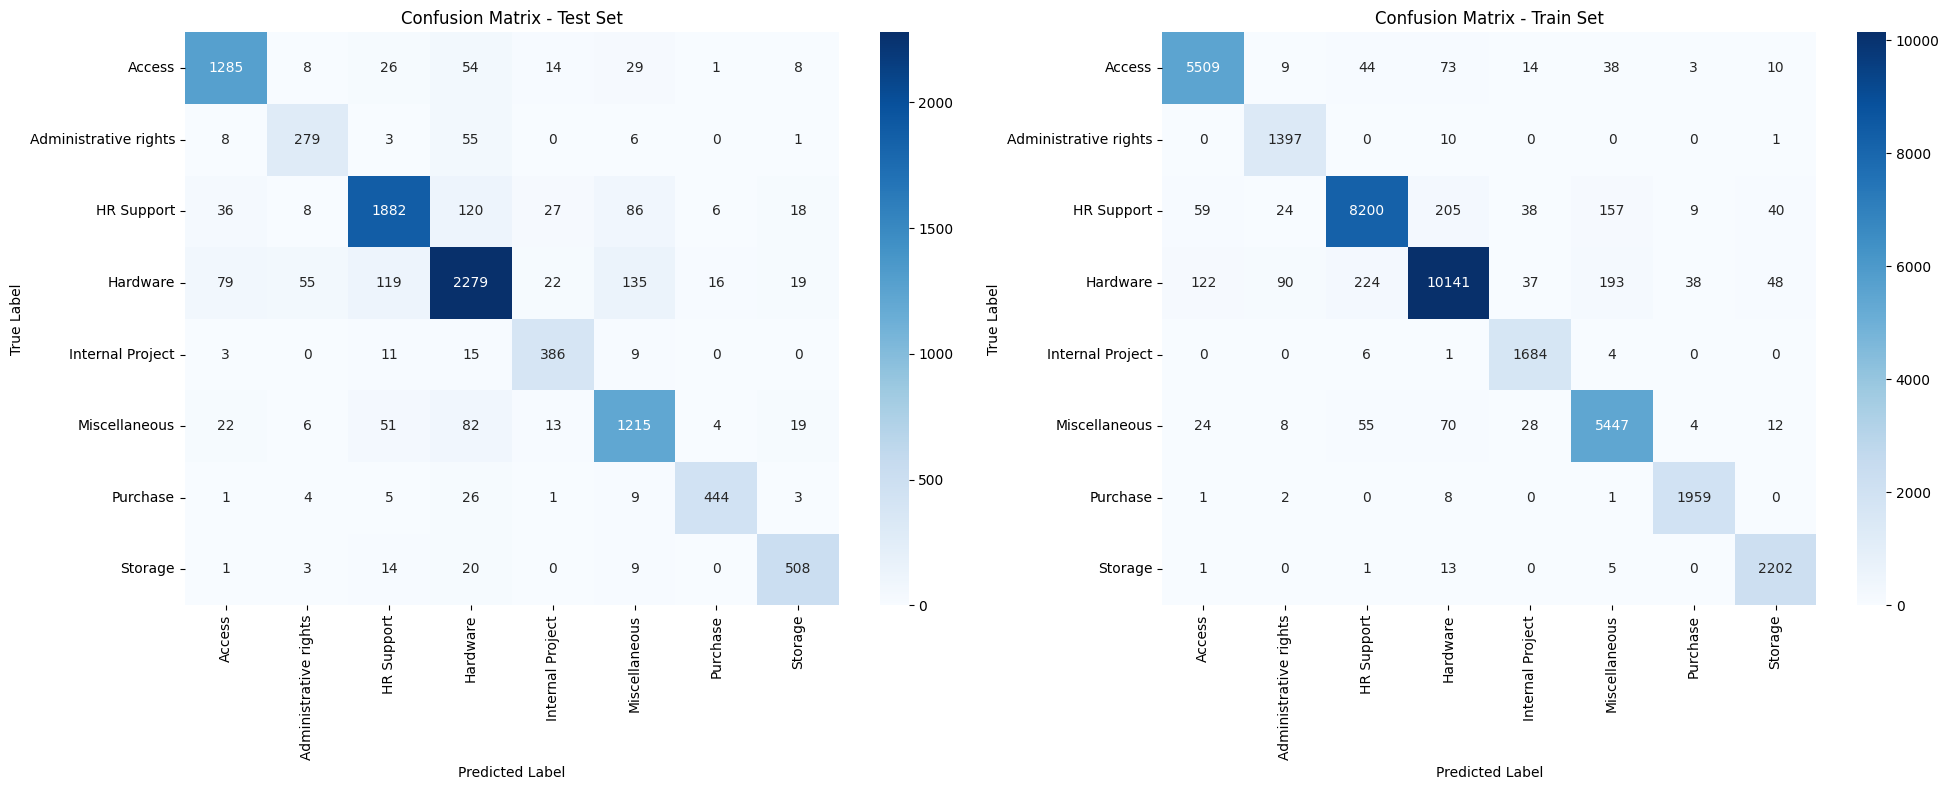

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get class labels
labels = model.named_steps["clf"].classes_

# --- Confusion Matrix for Test Set (already calculated 'cm_df' and 'pred') ---
cm_test = confusion_matrix(y_test, pred, labels=labels)
cm_df_test = pd.DataFrame(cm_test, index=labels, columns=labels)

# --- Confusion Matrix for Train Set ---
pred_train = model.predict(X_train)
cm_train = confusion_matrix(y_train, pred_train, labels=labels)
cm_df_train = pd.DataFrame(cm_train, index=labels, columns=labels)

# Plotting the confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Test Confusion Matrix Plot
sns.heatmap(cm_df_test, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix - Test Set')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Train Confusion Matrix Plot
sns.heatmap(cm_df_train, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Confusion Matrix - Train Set')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

samples = [
  # Obvios
  "I can’t log in to my corporate account. It says my password is incorrect and I’m locked out.",
  "Please grant me local administrator rights to install approved software on my workstation.",
  "My laptop won’t power on. The charging light is off and the battery won’t charge.",
  "I need help updating my employee profile and benefits information in the HR portal.",
  "My mailbox is full and I can’t send emails. I need more email storage quota.",
  "Request to purchase a new monitor and docking station for my workstation.",
  "Status update needed: please add me to the internal project Jira board and assign tasks.",
  "How do I set up email signature and out-of-office replies?",

  # Ambiguos
  "I can’t install the VPN client because it says I don’t have permission.",
  "I can’t access the HR portal; it keeps saying ‘unauthorized’.",
  "My laptop is slow and I keep getting ‘disk space low’ warnings.",
  "Please purchase extra storage for my team’s shared folder.",
  "I need access to the internal project repository and the documentation site.",
  "Need admin rights to install a printer driver on my PC.",
  "We need help onboarding a new hire: access to tools, laptop, and HR setup.",
]

proba = model.predict_proba(samples)
classes = model.named_steps["clf"].classes_

rows = []
for text, p in zip(samples, proba):
    top3_idx = np.argsort(p)[::-1][:3]
    rows.append({
        "text": text[:80] + ("..." if len(text) > 80 else ""),
        "pred": classes[int(np.argmax(p))],
        "conf_%": round(float(np.max(p))*100, 1),
        "top1": f"{classes[top3_idx[0]]} ({p[top3_idx[0]]*100:.1f}%)",
        "top2": f"{classes[top3_idx[1]]} ({p[top3_idx[1]]*100:.1f}%)",
        "top3": f"{classes[top3_idx[2]]} ({p[top3_idx[2]]*100:.1f}%)",
    })

pd.DataFrame(rows)


,text,pred,conf_%,top1,top2,top3
0,I can’t log in to my corporate account. It say...,Access,96.5,Access (96.5%),Purchase (1.9%),Administrative rights (0.9%)
1,Please grant me local administrator rights to ...,Administrative rights,69.1,Administrative rights (69.1%),Miscellaneous (17.6%),Purchase (7.3%)
2,My laptop won’t power on. The charging light i...,Hardware,94.4,Hardware (94.4%),Storage (1.3%),Purchase (1.2%)
3,I need help updating my employee profile and b...,Hardware,64.5,Hardware (64.5%),Miscellaneous (8.3%),HR Support (6.2%)
4,My mailbox is full and I can’t send emails. I ...,Storage,93.9,Storage (93.9%),Administrative rights (4.8%),Hardware (0.5%)
5,Request to purchase a new monitor and docking ...,Hardware,75.2,Hardware (75.2%),HR Support (11.3%),Administrative rights (7.8%)
6,Status update needed: please add me to the int...,Miscellaneous,49.2,Miscellaneous (49.2%),Internal Project (45.2%),HR Support (3.4%)
7,How do I set up email signature and out-of-off...,Administrative rights,38.2,Administrative rights (38.2%),Storage (25.9%),Hardware (13.8%)
8,I can’t install the VPN client because it says...,Hardware,45.9,Hardware (45.9%),Administrative rights (23.9%),Access (11.6%)
9,I can’t access the HR portal; it keeps saying ...,Hardware,78.6,Hardware (78.6%),Administrative rights (8.9%),Storage (3.5%)


In [ ]:
import os
os.makedirs("models", exist_ok=True)


In [ ]:
import joblib
joblib.dump(model, "models/category_pipeline.joblib")
print("Modelo guardado:", os.path.getsize("models/category_pipeline.joblib"), "bytes")


Modelo guardado: 11743388 bytes


In [ ]:
import json
from datetime import datetime

THRESHOLDS = {
    "Access": 0.60,
    "Administrative rights": 0.65,
    "Hardware": 0.55,
    "HR Support": 0.60,
    "Internal Project": 0.55,
    "Miscellaneous": 0.70,
    "Purchase": 0.60,
    "Storage": 0.55
}

meta = {
    "model_name": "IT Service Ticket Classifier",
    "version": "v1.0",
    "created_at": datetime.utcnow().isoformat(),
    "labels": list(model.named_steps["clf"].classes_),
    "thresholds": THRESHOLDS,
    "default_threshold": 0.60,
    "review_label": "REVIEW"
}

with open("models/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

!ls -lh models


total 12M
-rw-r--r-- 1 root root 12M Dec 15 22:27 category_pipeline.joblib
-rw-r--r-- 1 root root 563 Dec 15 22:27 meta.json


/tmp/ipython-input-3495934852.py:18: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_at": datetime.utcnow().isoformat(),


In [ ]:
!zip -r it_ticket_models.zip models


  adding: models/ (stored 0%)
  adding: models/category_pipeline.joblib (deflated 36%)
  adding: models/meta.json (deflated 50%)


In [ ]:
from google.colab import files
files.download("it_ticket_models.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>